# Figure 4: embeddings, CTCF editing, and Integrated Gradients

Recompute the GM12878 bin embeddings, predictions, CTCF editing experiment,
and sequence/omics attributions from two input samples and one checkpoint.
All 13 result panels are embedded in this notebook; no log or result files
are created.

**Requirements:** Python 3.9+, PyTorch 2.0+, NumPy, SciPy, Matplotlib,
seaborn, scikit-learn, Captum, and IPython. The pure PyTorch Mamba and model
definitions are included below, so no external model package or compiled
Mamba extension is required. Input PKL files are read from `data/ctcf_editing`; the checkpoint location is configured below.

Run all cells in order. The default device is CPU; set `MAMBAHIC_DEVICE` to
a CUDA device such as `cuda:0` to use a GPU. The full 50-step attribution
calculation takes longer than inference alone.


## Imports

In [1]:
from __future__ import annotations
from pathlib import Path
from io import BytesIO
import math
import os
import pickle
import warnings

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from sklearn.manifold import TSNE
from captum.attr import IntegratedGradients
from IPython.display import Image, display

torch.set_num_threads(4)
torch.manual_seed(42)
np.random.seed(42)
# The CPU MKLDNN backward path failed numerical gradient checks in the
# original environment. Keep it disabled for input-gradient calculations.
torch.backends.mkldnn.enabled = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
plt.ioff();


## Inputs and parameters

The two PKL files must provide `sequence_one_hot`, `omics_signals`, and `hic_matrix`. The TAD partition is an experimental input. CTCF bins 260-270 are set to zero in the normalized input, and the target contact is `(264, 49)`.

In [2]:
# Locate the repository from the notebook directory or any parent directory.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((parent for parent in [cwd, *cwd.parents]
                     if (parent / "data").is_dir() and (parent / "notebooks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find the repository's data and notebooks directories.")

# MAMBAHIC_FIG4_ASSETS selects the checkpoint location.
ASSETS_ROOT = Path(os.environ.get(
    "MAMBAHIC_FIG4_ASSETS",
    "/mnt/nfs/clgou2/MambaHiC_202610/zhuyufeng_v2_notebooks/fig4/assets",
))
DATA_DIR = PROJECT_ROOT / "data" / "ctcf_editing"
WEIGHTS = ASSETS_ROOT / "weights/figure04/gm12878_train_64stride_best_model.pth"
DEVICE = torch.device(os.environ.get("MAMBAHIC_DEVICE", "cpu"))
IG_STEPS = 50
EMB_SAMPLE = "chr7_35584000_36608000"
EDIT_SAMPLE = "chr7_45824000_46848000"
TARGET_I, TARGET_J = 264, 49
EDIT_RANGE = (260, 271)  # Zero the normalized CTCF input in bins 260-270.
TAD_BOUNDARIES = [0, 75, 110, 160, 190, 360, 395, 512]
TAD_COLORS = ["blue", "red", "green", "orange", "purple", "brown", "pink"]
OMICS_NAMES = ["CTCF", "DNase", "H3K27ac", "H3K4me3"]
device = DEVICE


## Pure PyTorch Mamba

In [3]:
from __future__ import annotations

class Mamba(nn.Module):
    """Pure PyTorch compatibility implementation of mamba_ssm.Mamba.

    This matches the Mamba v1 parameter names used by the saved checkpoint.
    It is intended for CPU inference when the CUDA extension is unavailable.
    """

    def __init__(
        self,
        d_model: int,
        d_state: int = 16,
        d_conv: int = 4,
        expand: int = 2,
        dt_rank: int | str = "auto",
        dt_min: float = 0.001,
        dt_max: float = 0.1,
        dt_init: str = "random",
        dt_scale: float = 1.0,
        dt_init_floor: float = 1e-4,
        conv_bias: bool = True,
        bias: bool = False,
        use_fast_path: bool = True,
        layer_idx=None,
        device=None,
        dtype=None,
        **kwargs,
    ):
        super().__init__()
        factory_kwargs = {"device": device, "dtype": dtype}
        self.d_model = d_model
        self.d_state = d_state
        self.d_conv = d_conv
        self.expand = expand
        self.d_inner = int(self.expand * self.d_model)
        self.dt_rank = math.ceil(self.d_model / 16) if dt_rank == "auto" else int(dt_rank)

        self.in_proj = nn.Linear(self.d_model, self.d_inner * 2, bias=bias, **factory_kwargs)
        self.conv1d = nn.Conv1d(
            in_channels=self.d_inner,
            out_channels=self.d_inner,
            bias=conv_bias,
            kernel_size=d_conv,
            groups=self.d_inner,
            padding=d_conv - 1,
            **factory_kwargs,
        )
        self.activation = "silu"
        self.act = nn.SiLU()

        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + self.d_state * 2, bias=False, **factory_kwargs)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True, **factory_kwargs)

        dt_init_std = self.dt_rank**-0.5 * dt_scale
        if dt_init == "constant":
            nn.init.constant_(self.dt_proj.weight, dt_init_std)
        elif dt_init == "random":
            nn.init.uniform_(self.dt_proj.weight, -dt_init_std, dt_init_std)
        else:
            raise NotImplementedError

        dt = torch.exp(
            torch.rand(self.d_inner, **factory_kwargs) * (math.log(dt_max) - math.log(dt_min))
            + math.log(dt_min)
        ).clamp(min=dt_init_floor)
        inv_dt = dt + torch.log(-torch.expm1(-dt))
        with torch.no_grad():
            self.dt_proj.bias.copy_(inv_dt)
        self.dt_proj.bias._no_reinit = True

        A = torch.arange(1, self.d_state + 1, dtype=torch.float32, device=device).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.A_log._no_weight_decay = True
        self.D = nn.Parameter(torch.ones(self.d_inner, device=device))
        self.D._no_weight_decay = True
        self.out_proj = nn.Linear(self.d_inner, self.d_model, bias=bias, **factory_kwargs)

    def forward(self, hidden_states, inference_params=None):
        batch, seqlen, _ = hidden_states.shape

        xz = self.in_proj(hidden_states).transpose(1, 2)
        x, z = xz.chunk(2, dim=1)
        x = self.act(self.conv1d(x)[..., :seqlen])

        x_dbl = self.x_proj(x.transpose(1, 2).reshape(batch * seqlen, self.d_inner))
        dt, B, C = torch.split(x_dbl, [self.dt_rank, self.d_state, self.d_state], dim=-1)
        dt = self.dt_proj.weight @ dt.t()
        dt = dt.reshape(self.d_inner, batch, seqlen).permute(1, 0, 2).contiguous()
        B = B.reshape(batch, seqlen, self.d_state).transpose(1, 2).contiguous()
        C = C.reshape(batch, seqlen, self.d_state).transpose(1, 2).contiguous()

        y = self._selective_scan(x, dt, B, C, z)
        return self.out_proj(y.transpose(1, 2))

    def _selective_scan(self, u, delta, B, C, z):
        dtype_in = u.dtype
        u_f = u.float()
        delta_f = F.softplus(delta.float() + self.dt_proj.bias.float().view(1, -1, 1))
        A = -torch.exp(self.A_log.float())
        B_f = B.float()
        C_f = C.float()

        state = torch.zeros(u.shape[0], self.d_inner, self.d_state, device=u.device, dtype=torch.float32)
        ys = []
        for i in range(u.shape[-1]):
            delta_i = delta_f[:, :, i]
            deltaA = torch.exp(delta_i.unsqueeze(-1) * A.unsqueeze(0))
            deltaB_u = delta_i.unsqueeze(-1) * B_f[:, :, i].unsqueeze(1) * u_f[:, :, i].unsqueeze(-1)
            state = state * deltaA + deltaB_u
            y_i = torch.sum(state * C_f[:, :, i].unsqueeze(1), dim=-1)
            ys.append(y_i)

        y = torch.stack(ys, dim=-1)
        y = y + u_f * self.D.float().view(1, -1, 1)
        y = y * F.silu(z.float())
        return y.to(dtype=dtype_in)

## CNN-Mamba model

In [4]:
class DownsampleBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int, activation: str = "relu"):
        super().__init__()
        act = nn.GELU() if activation == "gelu" else nn.ReLU(inplace=True)
        self.block = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size, stride=stride, padding=kernel_size // 2),
            nn.BatchNorm1d(out_channels),
            act,
        )

    def forward(self, x):
        return self.block(x)


class DeepFeatureResBlock(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 7):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Conv1d(channels, channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm1d(channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class HybridCNNMambaEncoder(nn.Module):
    def __init__(self, in_channels: int, d_model: int = 128, num_cnn_blocks: int = 3, num_mamba_layers: int = 3, is_sequence: bool = True):
        super().__init__()
        self.is_sequence = is_sequence
        self.use_bidirectional_wrapper = True
        if self.is_sequence:
            self.downsampler = nn.Sequential(
                DownsampleBlock(in_channels, 48, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(48, 96, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(96, d_model, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(d_model, d_model, kernel_size=5, stride=4, activation="gelu"),
                DownsampleBlock(d_model, d_model, kernel_size=5, stride=4, activation="gelu"),
            )
        else:
            self.downsampler = nn.Sequential(nn.Conv1d(in_channels, d_model, kernel_size=1), nn.GELU())
        self.cnn_feature_extractor = nn.Sequential(*[DeepFeatureResBlock(d_model) for _ in range(num_cnn_blocks)])
        self.mamba_layers = nn.ModuleList([Mamba(d_model=d_model, d_state=16, d_conv=4, expand=2) for _ in range(num_mamba_layers)])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        x = self.downsampler(x)
        x = self.cnn_feature_extractor(x).transpose(1, 2)
        x = self.norm(x)
        if not self.use_bidirectional_wrapper:
            for layer in self.mamba_layers:
                x = x + layer(x)
            return x.transpose(1, 2)
        for mamba_layer in self.mamba_layers:
            x_fw = mamba_layer(x)
            x_bw = torch.flip(mamba_layer(torch.flip(x, dims=[1])), dims=[1])
            x = x + x_fw + x_bw
        return x.transpose(1, 2)


class SimpleFusion(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.fusion_conv = nn.Sequential(
            nn.Conv1d(in_channels * 2, out_channels, kernel_size=1),
            nn.BatchNorm1d(out_channels),
            nn.GELU(),
        )

    def forward(self, seq_emb, omics_emb):
        return self.fusion_conv(torch.cat([seq_emb, omics_emb], dim=1))


class ConvResBlock(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 3):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.BatchNorm2d(channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.BatchNorm2d(channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class PracticalOuterProductDecoder(nn.Module):
    def __init__(self, in_channels: int = 128, bottleneck_channels: int = 16, num_blocks: int = 4):
        super().__init__()
        self.bottleneck = nn.Conv1d(in_channels, bottleneck_channels, 1)
        self.initial_conv = nn.Conv2d(bottleneck_channels * 2, 64, 1)
        self.res_blocks = nn.Sequential(*[ConvResBlock(64) for _ in range(num_blocks)])
        self.final_conv = nn.Conv2d(64, 1, 3, padding=1)

    def forward(self, fused_embedding):
        _, _, length = fused_embedding.shape
        bottleneck_emb = self.bottleneck(fused_embedding)
        x1 = bottleneck_emb.unsqueeze(3).expand(-1, -1, length, length)
        x2 = bottleneck_emb.unsqueeze(2).expand(-1, -1, length, length)
        x = self.initial_conv(torch.cat([x1, x2], dim=1))
        x = self.final_conv(self.res_blocks(x))
        return (x + x.transpose(-2, -1)) / 2


class CNNMambaHybridModelLegacy(nn.Module):
    """Original GM12878 Figure 04 model matching output_GM12878_train_64stride/best_model.pth."""

    def __init__(
        self,
        seq_in_channels: int = 4,
        num_omics_features: int = 4,
        d_model: int = 128,
        fusion_out_dim: int = 128,
        num_cnn_blocks: int = 3,
        num_mamba_layers: int = 3,
        decoder_bottleneck_channels: int = 48,
        decoder_num_blocks: int = 6,
    ):
        super().__init__()
        self.seq_encoder = HybridCNNMambaEncoder(seq_in_channels, d_model, num_cnn_blocks, num_mamba_layers, is_sequence=True)
        self.omics_encoder = HybridCNNMambaEncoder(num_omics_features, d_model, num_cnn_blocks, num_mamba_layers, is_sequence=False)
        self.fusion_module = SimpleFusion(in_channels=d_model, out_channels=fusion_out_dim)
        self.decoder = PracticalOuterProductDecoder(fusion_out_dim, decoder_bottleneck_channels, decoder_num_blocks)

    def encode_fused(self, seq, omics):
        seq_emb = self.seq_encoder(seq)
        omics_emb = self.omics_encoder(omics)
        return self.fusion_module(seq_emb, omics_emb)

    def forward(self, seq, omics):
        return self.decoder(self.encode_fused(seq, omics)).squeeze(1)

## Load the checkpoint and input helpers

In [5]:
class NumpyCompatibleUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if np.lib.NumpyVersion(np.__version__) < "2.0.0":
            if module == "numpy._core" or module.startswith("numpy._core."):
                module = module.replace("numpy._core", "numpy.core", 1)
        return super().find_class(module, name)


def load_sample(path, smooth_hic, sigma=1.0):
    with path.open("rb") as handle:
        data = NumpyCompatibleUnpickler(handle).load()
    sequence = torch.from_numpy(data["sequence_one_hot"].astype(np.float32))
    omics = torch.from_numpy(data["omics_signals"].astype(np.float32))
    hic = np.log2(data["hic_matrix"].astype(np.float32) + 1.0)
    if smooth_hic:
        hic = gaussian_filter(hic, sigma=sigma)
    np.fill_diagonal(hic, 0.0)
    return sequence, omics, torch.from_numpy(hic)


def show_figure(figure, dpi=200):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=dpi)
        display(Image(data=buffer.getvalue()))
    plt.close(figure)


with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="TypedStorage is deprecated.*")
    state = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
if "model_state_dict" in state:
    state = state["model_state_dict"]
elif "state_dict" in state:
    state = state["state_dict"]
state = {key.removeprefix("module."): value for key, value in state.items()}
model = CNNMambaHybridModelLegacy(seq_in_channels=4, num_omics_features=4)
model.load_state_dict(state, strict=True)
model = model.to(DEVICE).eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)


## Extract fused embeddings and fit t-SNE

The original t-SNE parameters and orthogonal orientation alignment are retained.

In [6]:
(seq, omics, hic) = load_sample(DATA_DIR / f'{EMB_SAMPLE}.pkl', smooth_hic=True)
with torch.no_grad():
    (pred, fused) = (None, None)
    pred = model(seq.unsqueeze(0).to(device), omics.unsqueeze(0).to(device)).squeeze(0).cpu().numpy()
    fused = model.encode_fused(seq.unsqueeze(0).to(device), omics.unsqueeze(0).to(device))
fused_np = fused.squeeze(0).cpu().numpy().T
emb_2d = TSNE(n_components=2, perplexity=30, learning_rate='auto', init='pca', random_state=42).fit_transform(fused_np)
ALIGN = np.array([[-0.227283, 0.973829], [0.973829, 0.227283]])
emb_2d = (emb_2d - emb_2d.mean(0)) @ ALIGN.T
real = hic.numpy()


## (b) Embeddings colored by TAD

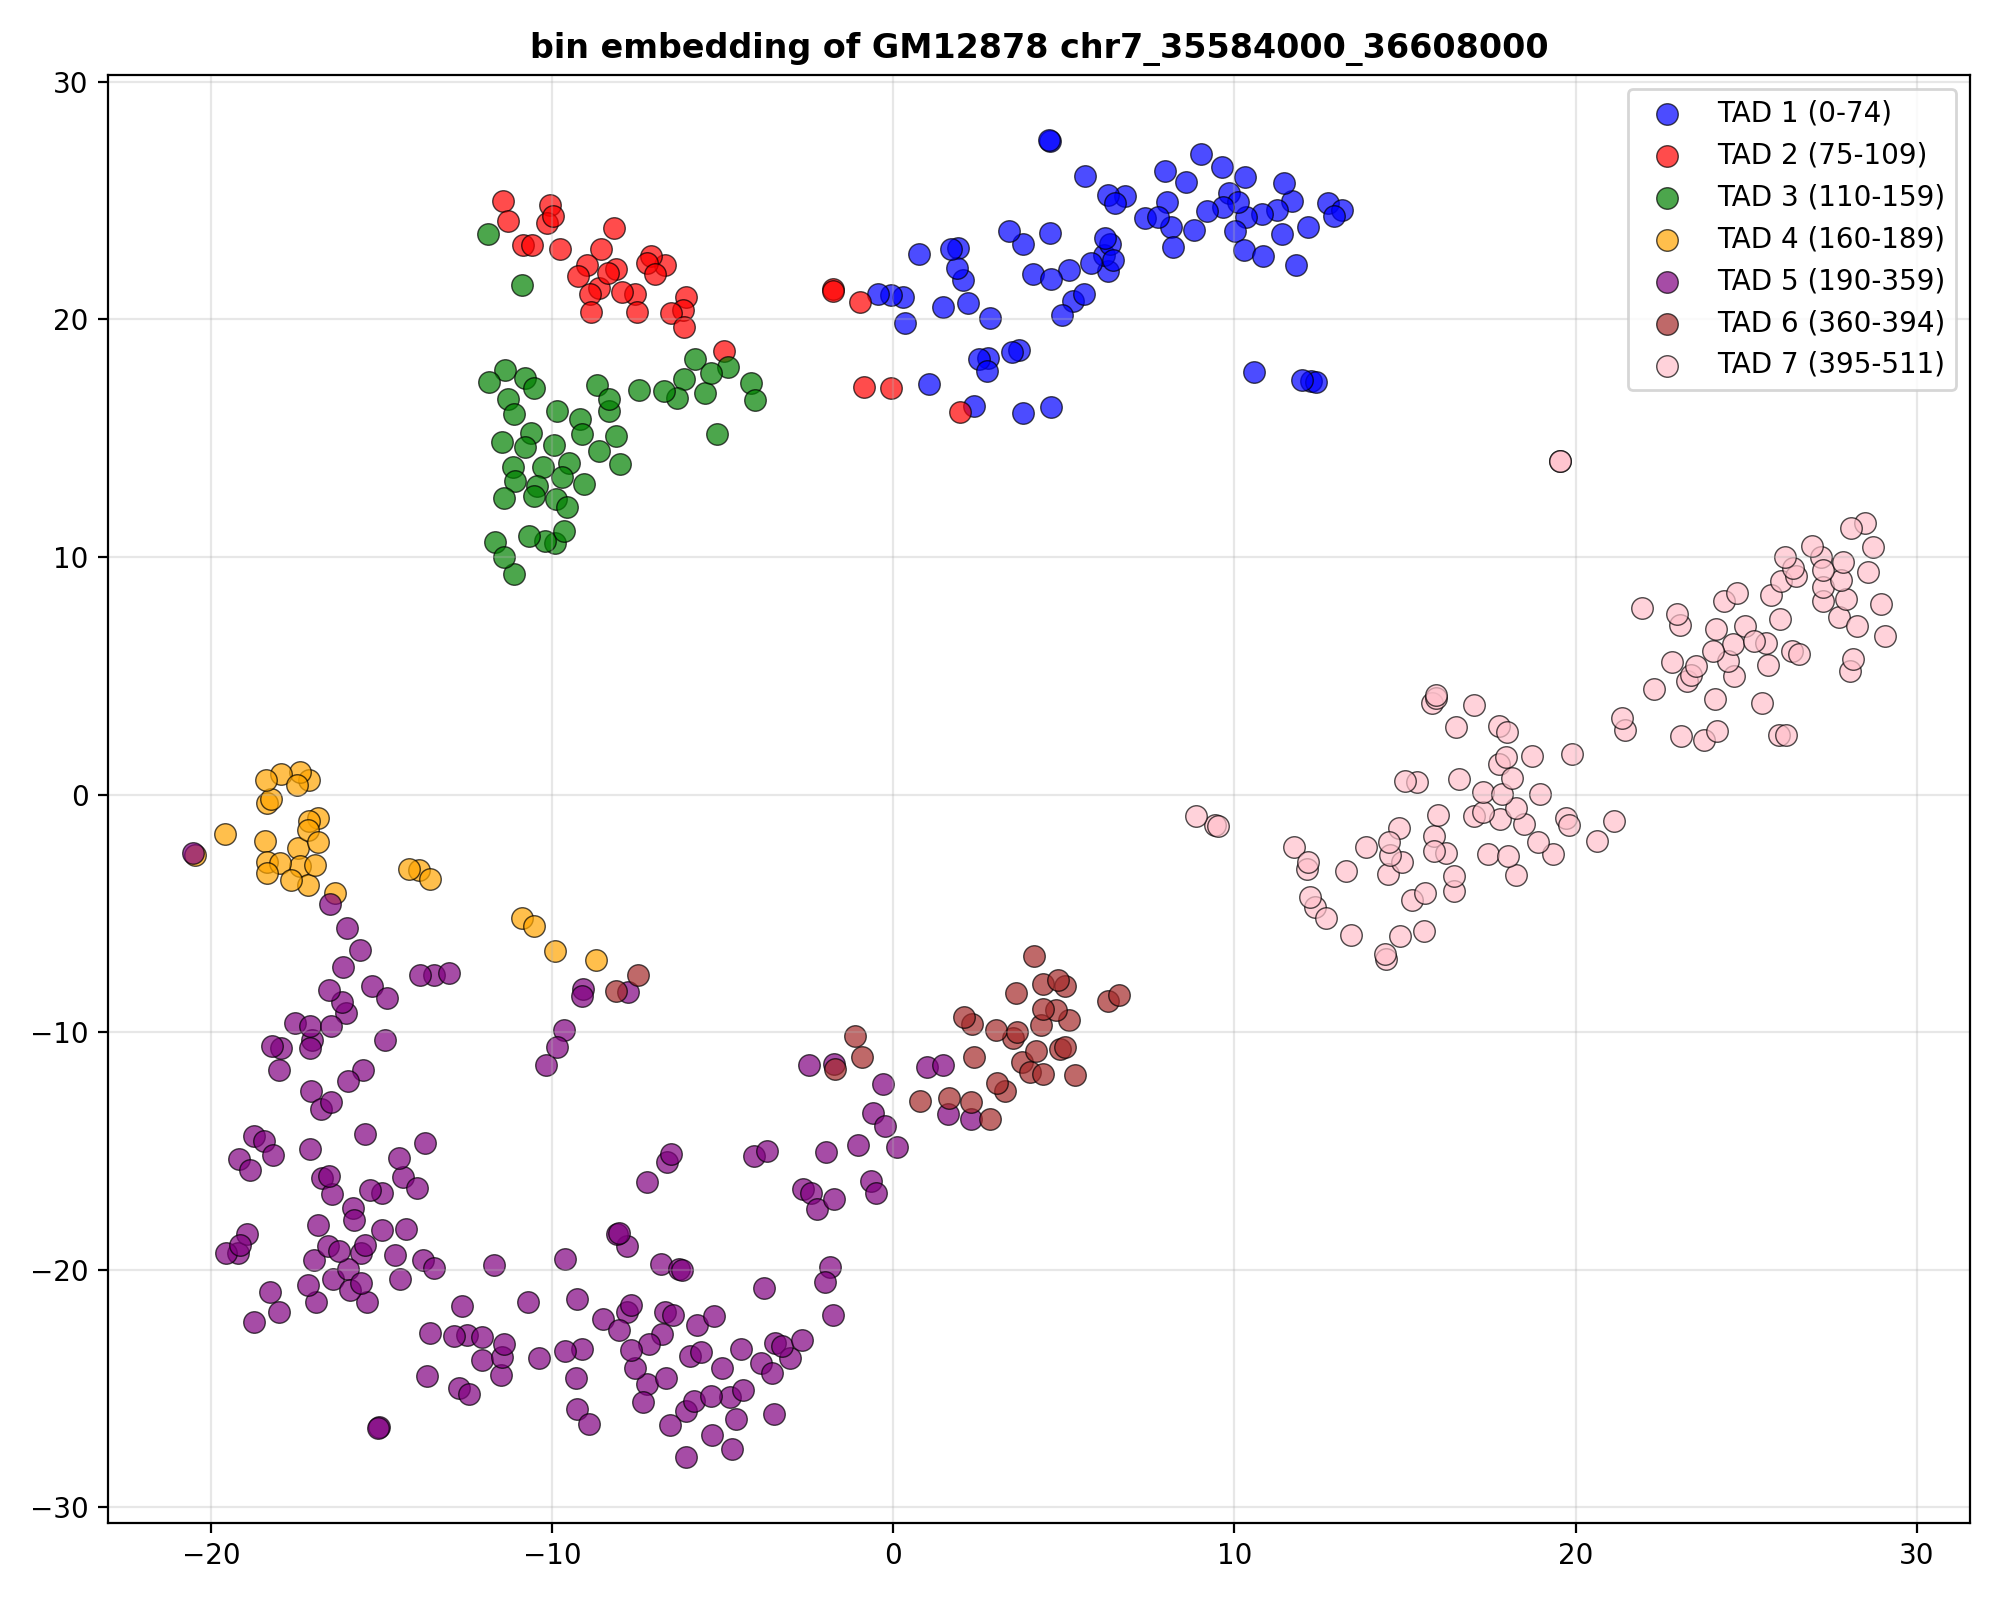

In [7]:
(fig, ax) = plt.subplots(figsize=(10, 8))
for i in range(len(TAD_BOUNDARIES) - 1):
    (s, e) = (TAD_BOUNDARIES[i], TAD_BOUNDARIES[i + 1])
    if s < len(emb_2d) and e <= len(emb_2d):
        ax.scatter(emb_2d[s:e, 0], emb_2d[s:e, 1], alpha=0.7, s=60, color=TAD_COLORS[i % len(TAD_COLORS)], label=f'TAD {i + 1} ({s}-{e - 1})', edgecolors='black', linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.set_title(f'bin embedding of GM12878 {EMB_SAMPLE}', fontweight='bold')
ax.legend()
fig.tight_layout()
show_figure(fig, dpi=200)


## (c) Observed Hi-C and TAD boundaries

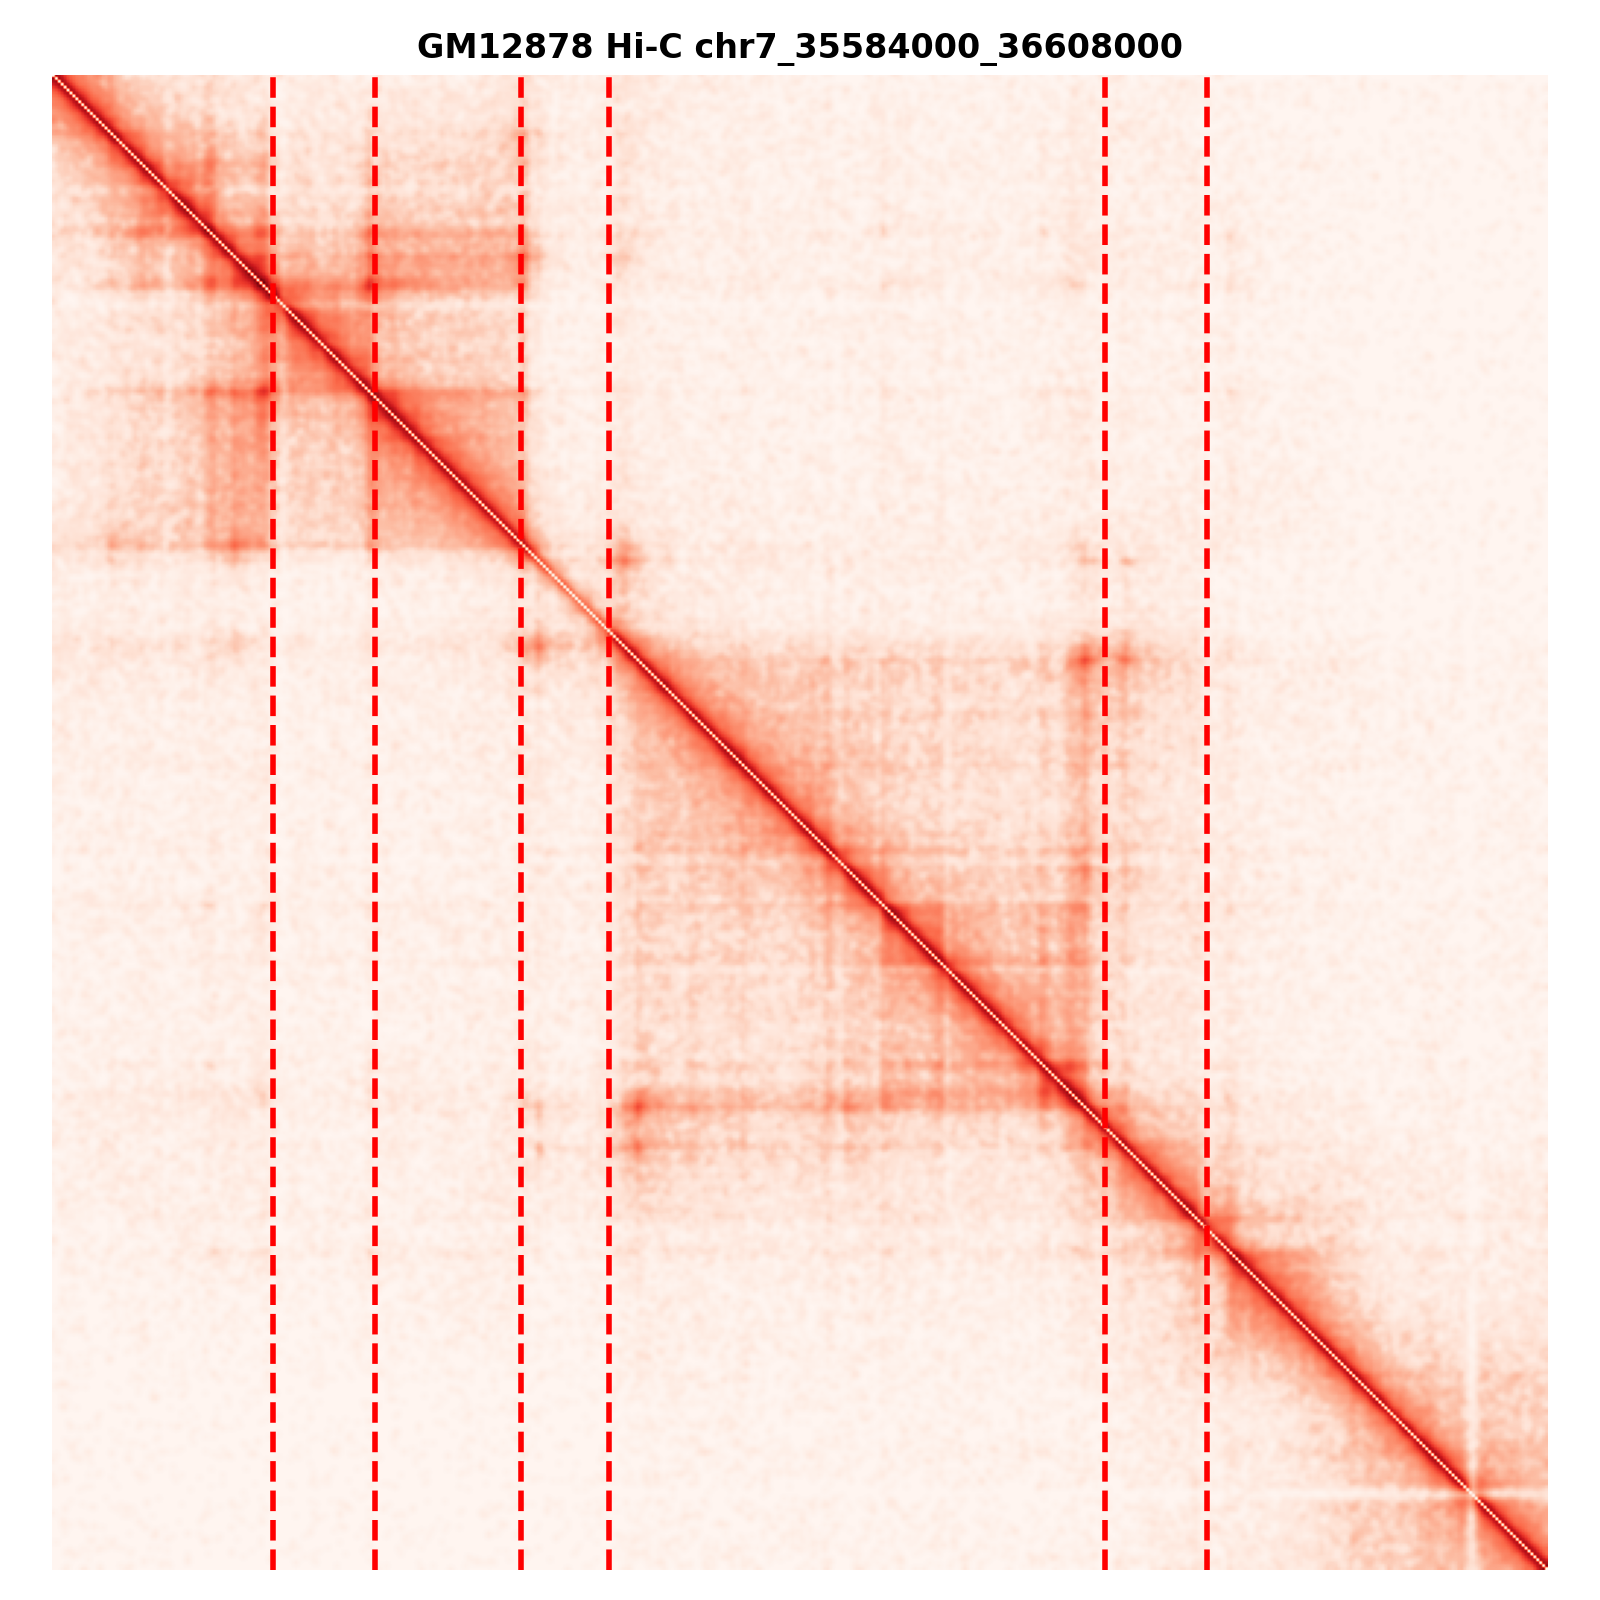

In [8]:
(fig, ax) = plt.subplots(figsize=(8, 8))
ax.imshow(real, cmap='Reds')
ax.axis('off')
ax.set_title(f'GM12878 Hi-C {EMB_SAMPLE}', fontweight='bold')
for b in TAD_BOUNDARIES[1:-1]:
    ax.axvline(x=b, color='red', linestyle='--', linewidth=2)
fig.tight_layout()
show_figure(fig, dpi=200)


## Embedding and prediction comparison

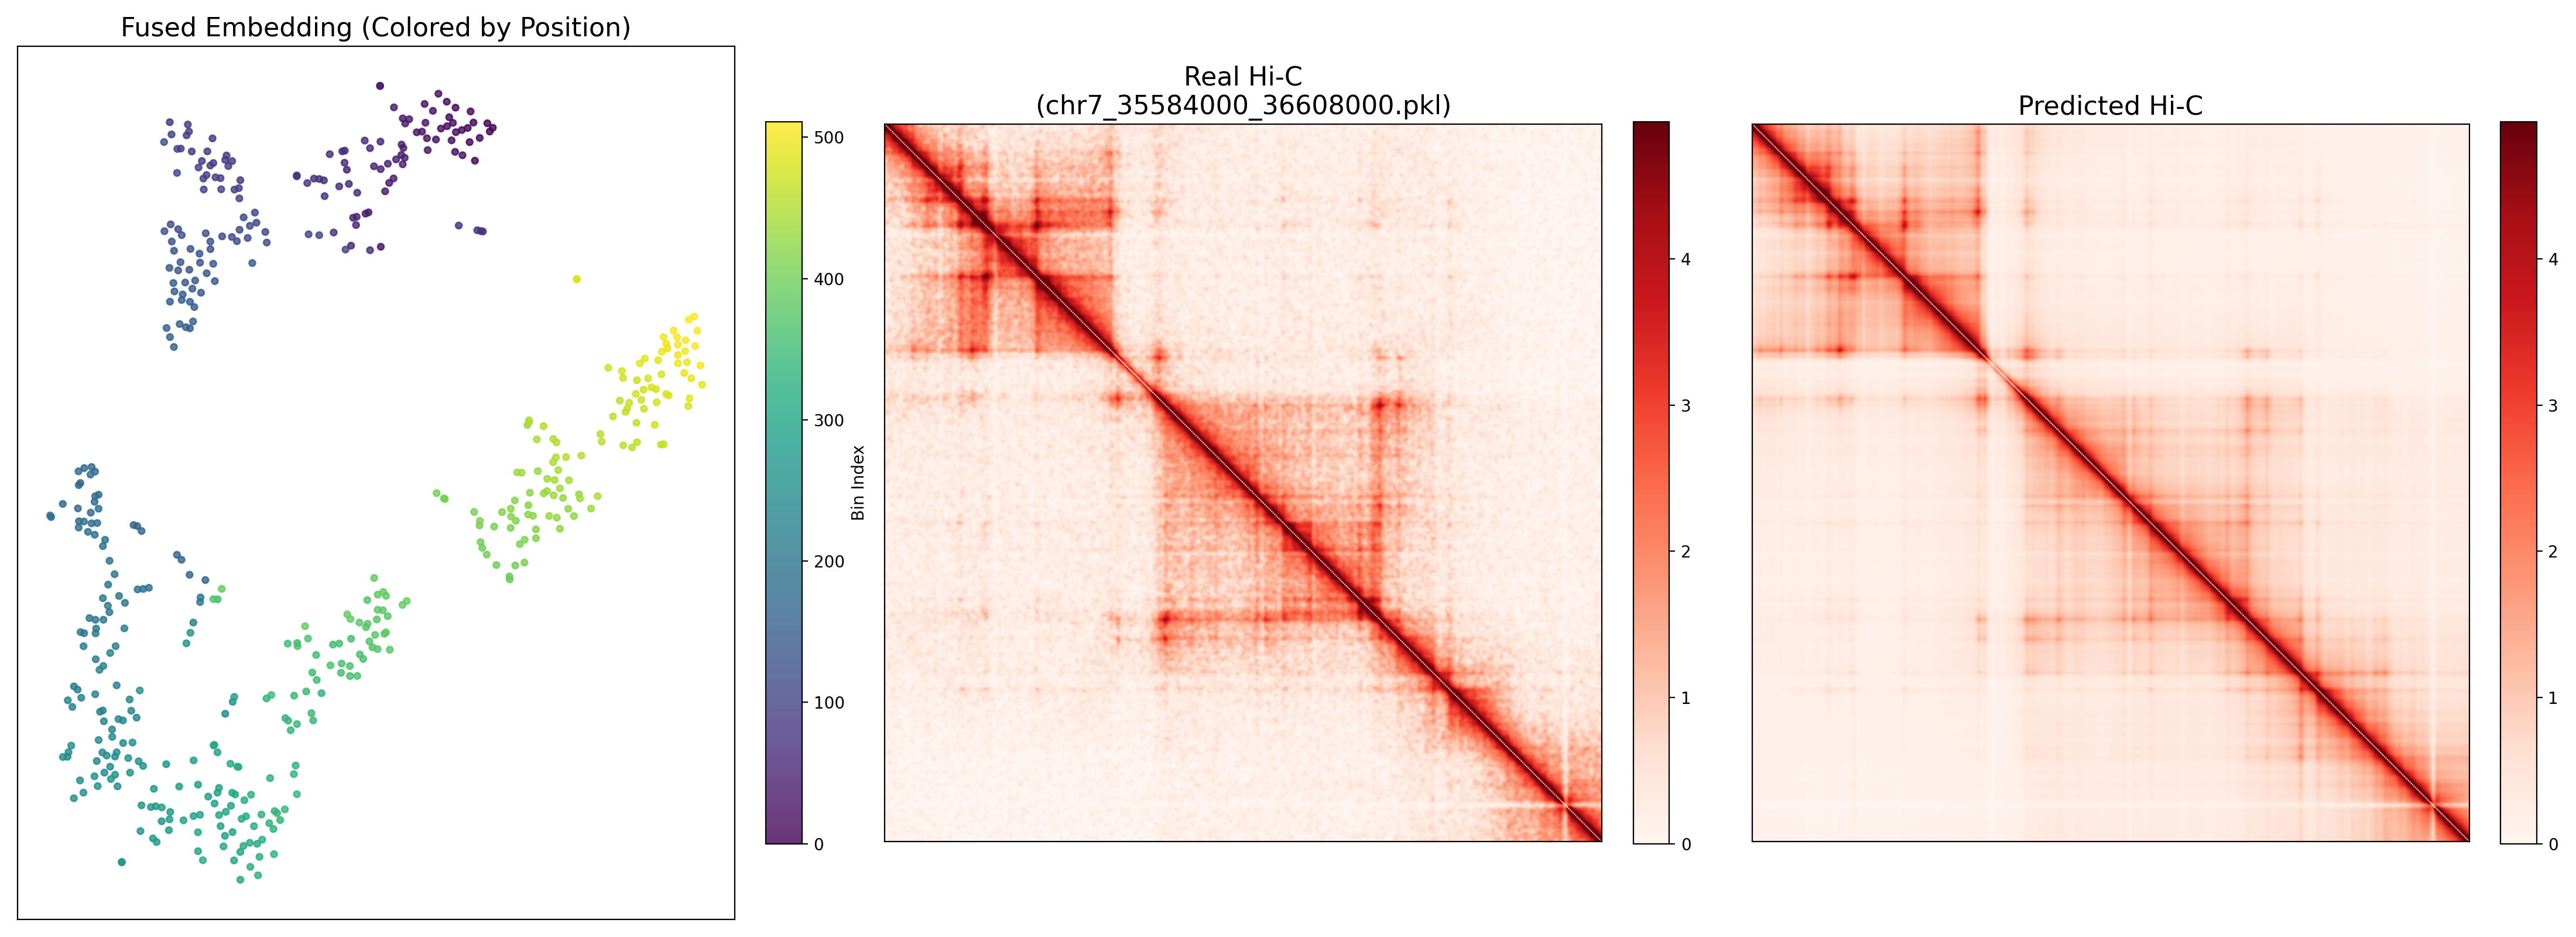

In [9]:
vmax = np.percentile(real[real > 0], 99) if (real > 0).any() else 1.0
(fig, axes) = plt.subplots(1, 3, figsize=(22, 8))
sc = axes[0].scatter(emb_2d[:, 0], emb_2d[:, 1], c=np.arange(len(emb_2d)), cmap='viridis', s=15, alpha=0.8)
axes[0].set_title('Fused Embedding (Colored by Position)', fontsize=16)
axes[0].set_xticks([])
axes[0].set_yticks([])
fig.colorbar(sc, ax=axes[0], fraction=0.046, pad=0.04).set_label('Bin Index')
im = axes[1].imshow(real, cmap='Reds', vmin=0, vmax=vmax)
axes[1].set_title(f'Real Hi-C\n({EMB_SAMPLE}.pkl)', fontsize=16)
axes[1].set_xticks([])
axes[1].set_yticks([])
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
im2 = axes[2].imshow(pred, cmap='Reds', vmin=0, vmax=vmax)
axes[2].set_title('Predicted Hi-C', fontsize=16)
axes[2].set_xticks([])
axes[2].set_yticks([])
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
fig.tight_layout()
show_figure(fig, dpi=200)


## (d) Predictions before CTCF editing

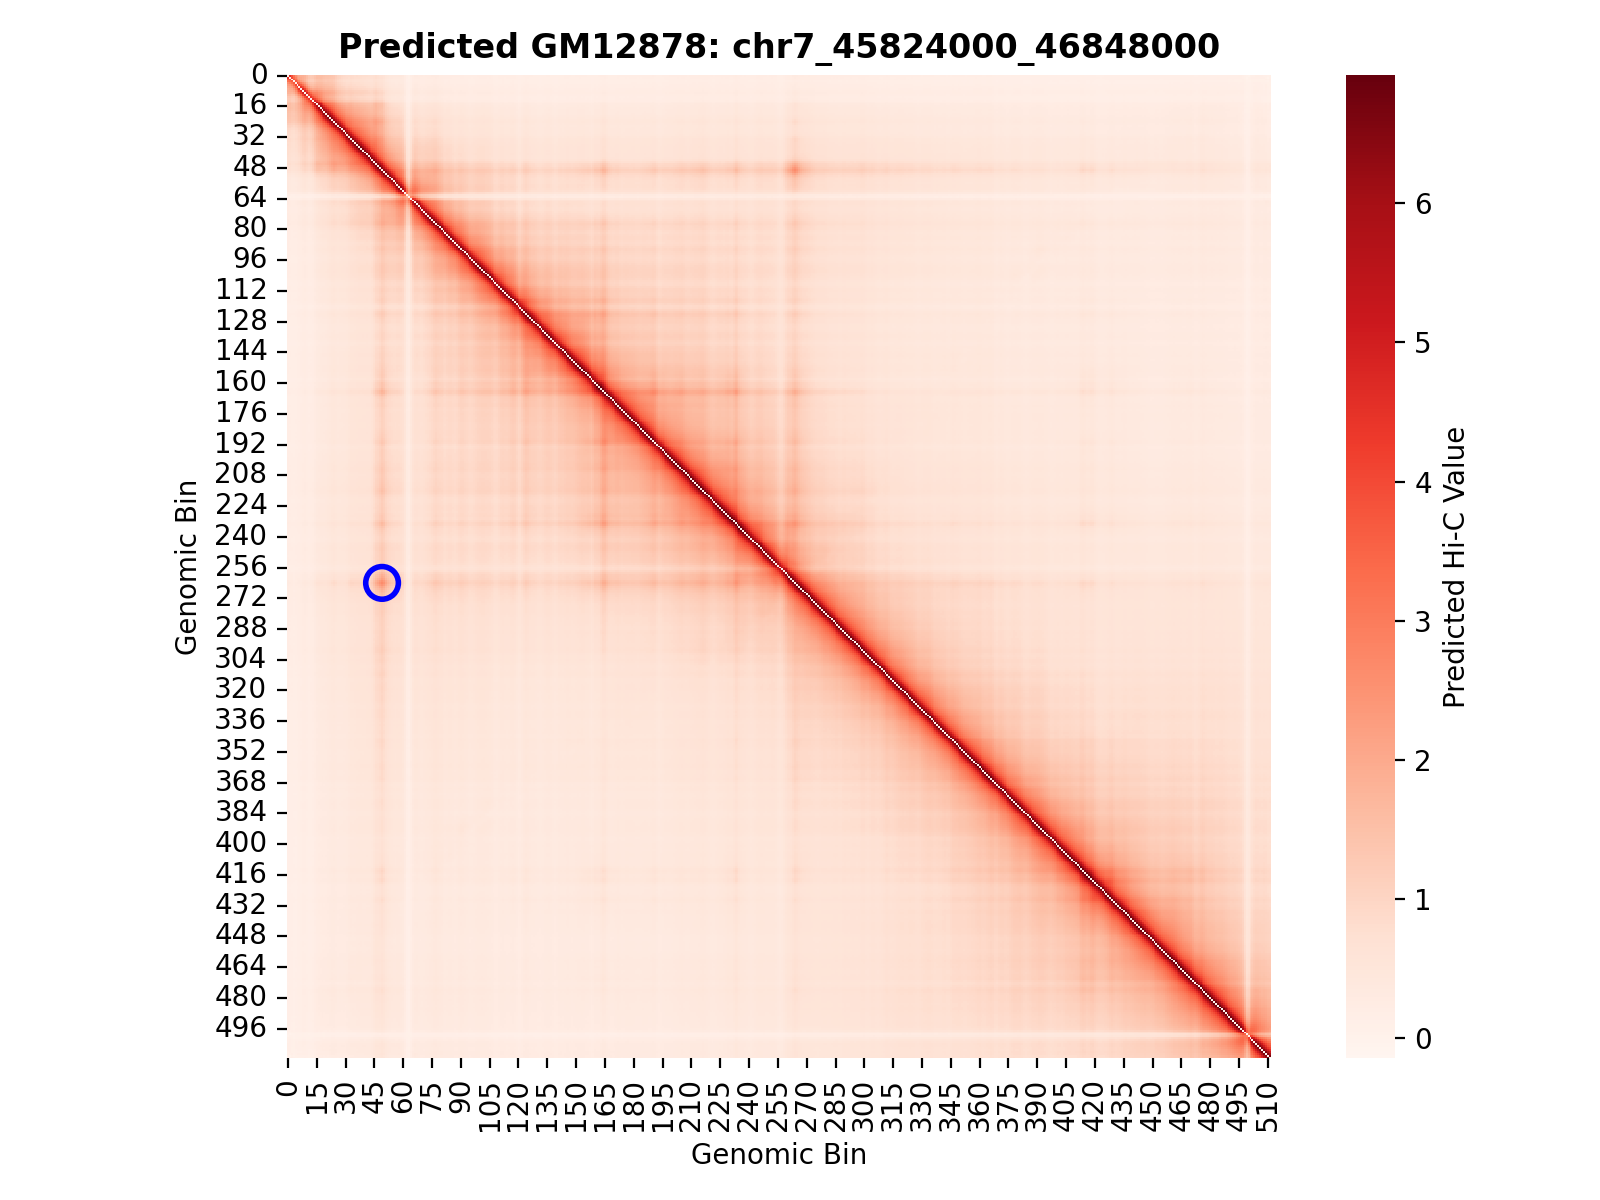

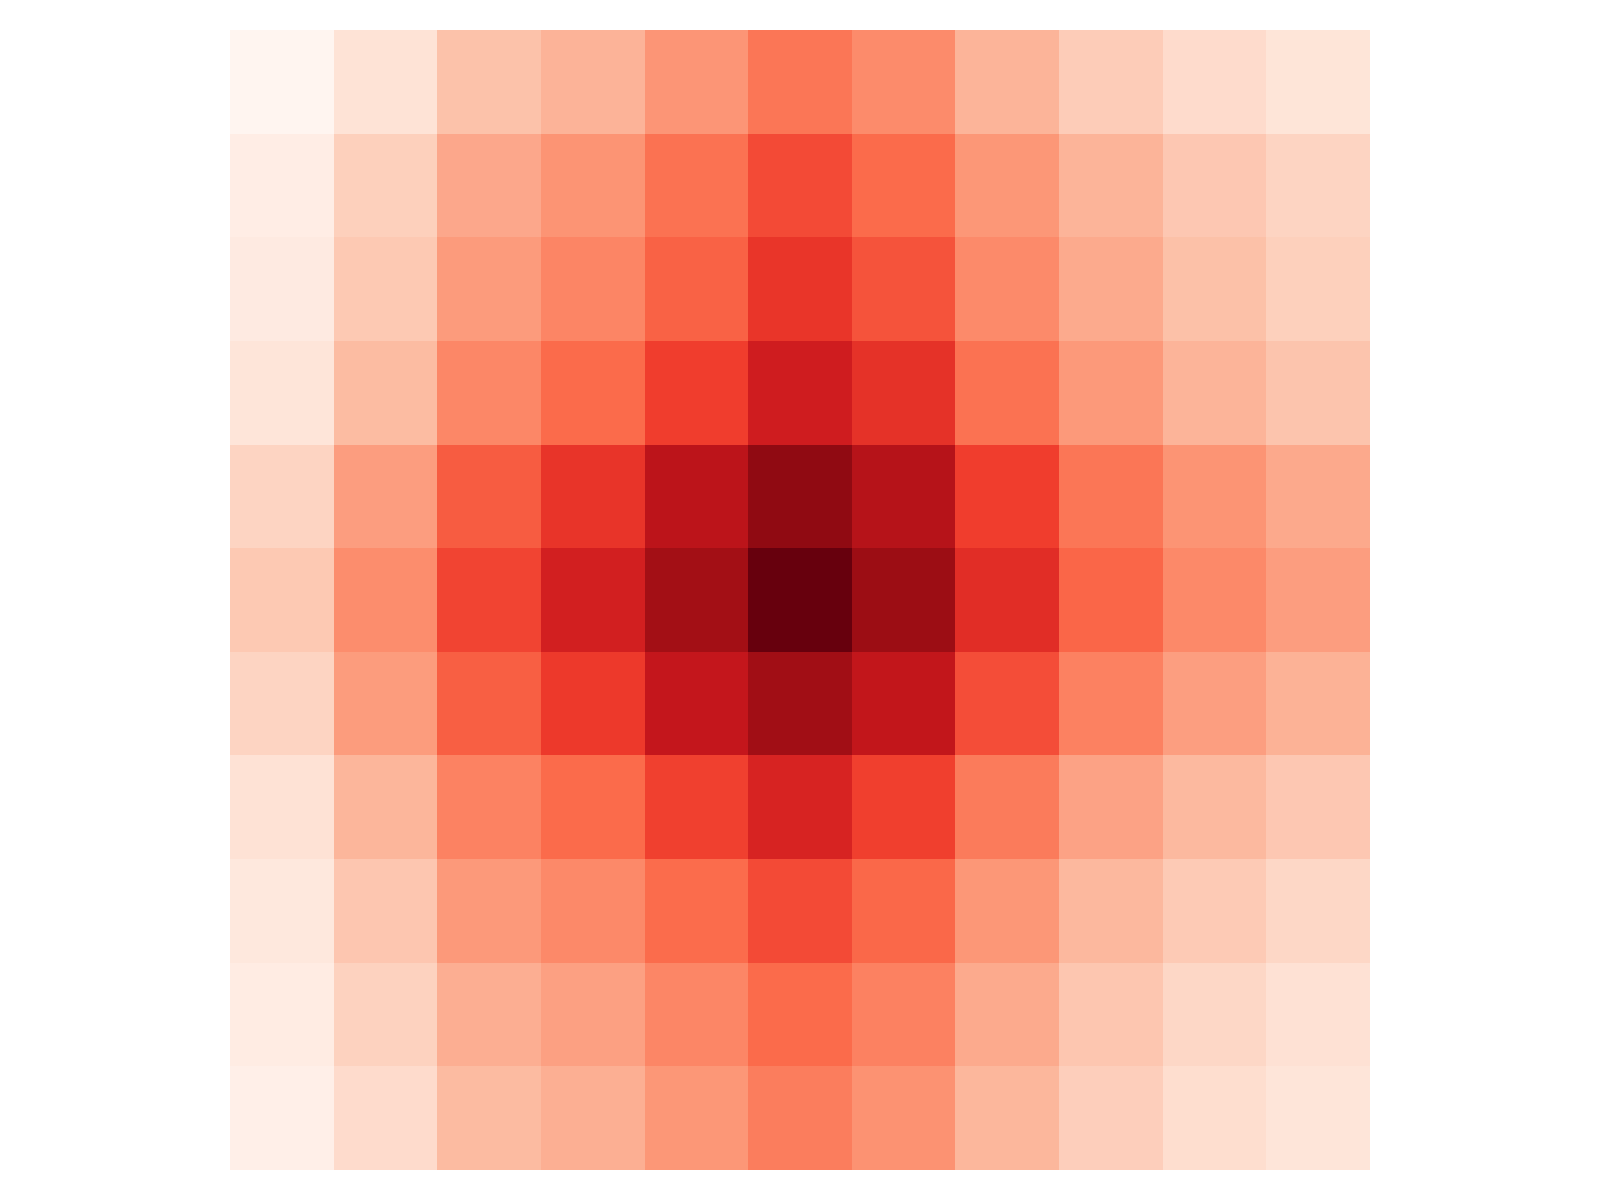

In [10]:
(seq, omics, hic) = load_sample(DATA_DIR / f'{EDIT_SAMPLE}.pkl', smooth_hic=False)
seq_b = seq.unsqueeze(0).to(device)
omics_b = omics.unsqueeze(0).to(device)
with torch.no_grad():
    pred_before = model(seq_b, omics_b).squeeze(0).cpu().numpy()
    omics_edit = omics_b.clone()
    omics_edit[:, 0, EDIT_RANGE[0]:EDIT_RANGE[1]] = 0
    pred_after = model(seq_b, omics_edit).squeeze(0).cpu().numpy()

def pred_panel(matrix, title, with_circle=True):
    (fig, ax) = plt.subplots(figsize=(8, 6))
    sns.heatmap(matrix, cmap='Reds', cbar_kws={'label': 'Predicted Hi-C Value'}, square=True, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Genomic Bin')
    ax.set_ylabel('Genomic Bin')
    if with_circle:
        from matplotlib.patches import Circle
        ax.add_patch(Circle((TARGET_J + 0.5, TARGET_I + 0.5), radius=8.5, fill=False, edgecolor='blue', linewidth=2.0))
    fig.tight_layout()
    show_figure(fig, dpi=200)

def inset_panel(matrix, title):
    radius = 5
    (tli, bri) = (max(0, TARGET_I - radius), min(matrix.shape[0], TARGET_I + radius + 1))
    (tlj, brj) = (max(0, TARGET_J - radius), min(matrix.shape[1], TARGET_J + radius + 1))
    local = matrix[tli:bri, tlj:brj]
    (fig, ax) = plt.subplots(figsize=(8, 6))
    sns.heatmap(local, cmap='Reds', square=True, fmt='.3f', cbar=False, xticklabels=False, yticklabels=False, ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.tight_layout()
    show_figure(fig, dpi=200)
    return local
pred_panel(pred_before, f'Predicted GM12878: {EDIT_SAMPLE}')
inset_panel(pred_before, 'before')


## Check input gradients

Verify the input gradients against finite differences at the input and at the midpoint of the attribution path before computing attributions.

In [11]:
def check_input_gradient(sequence, omics):
    sequence = sequence.detach().clone().requires_grad_(True)
    omics = omics.detach().clone().requires_grad_(True)
    value = model(sequence, omics)[0, TARGET_I, TARGET_J]
    seq_grad, omics_grad = torch.autograd.grad(value, (sequence, omics))
    assert torch.isfinite(seq_grad).all() and torch.isfinite(omics_grad).all()
    index = tuple(np.unravel_index(int(omics_grad.abs().argmax()), tuple(omics_grad.shape)))
    analytic = float(omics_grad[index])
    epsilon = 1e-3
    plus, minus = omics.detach().clone(), omics.detach().clone()
    plus[index] += epsilon
    minus[index] -= epsilon
    with torch.inference_mode():
        numerical = float((model(sequence.detach(), plus)[0, TARGET_I, TARGET_J] -
                           model(sequence.detach(), minus)[0, TARGET_I, TARGET_J]) / (2 * epsilon))
    assert np.isclose(analytic, numerical, rtol=0.03, atol=0.002), "Input-gradient check failed."


check_input_gradient(seq_b, omics_b)
check_input_gradient(seq_b * 0.5, omics_b * 0.5)


## (e-f) Compute 50-step Integrated Gradients

Sequence and omics use zero baselines, Gauss-Legendre integration, and an internal batch size of 2. A completeness check compares the summed attributions with the input-minus-baseline prediction difference.

In [12]:
def model_forward_for_pixel(sequence, omics_signals):
    return model(sequence, omics_signals)[:, TARGET_I, TARGET_J]


ig = IntegratedGradients(model_forward_for_pixel)
attrs = ig.attribute(
    inputs=(seq_b, omics_b),
    baselines=(torch.zeros_like(seq_b), torch.zeros_like(omics_b)),
    n_steps=IG_STEPS,
    internal_batch_size=2,
)
seq_attr = attrs[0].squeeze(0).detach().cpu().numpy()
omics_attr = attrs[1].squeeze(0).detach().cpu().numpy()
assert np.isfinite(seq_attr).all() and np.isfinite(omics_attr).all()

with torch.inference_mode():
    baseline_prediction = float(model(
        torch.zeros_like(seq_b), torch.zeros_like(omics_b)
    )[0, TARGET_I, TARGET_J])
attribution_sum = float(
    np.sum(seq_attr, dtype=np.float64) + np.sum(omics_attr, dtype=np.float64)
)
prediction_difference = float(pred_before[TARGET_I, TARGET_J]) - baseline_prediction
ig_relative_error = abs(attribution_sum - prediction_difference) / max(abs(prediction_difference), 1e-8)
assert ig_relative_error <= 0.05, "Integrated Gradients completeness error exceeds 5%."


## Sequence and omics attribution panels

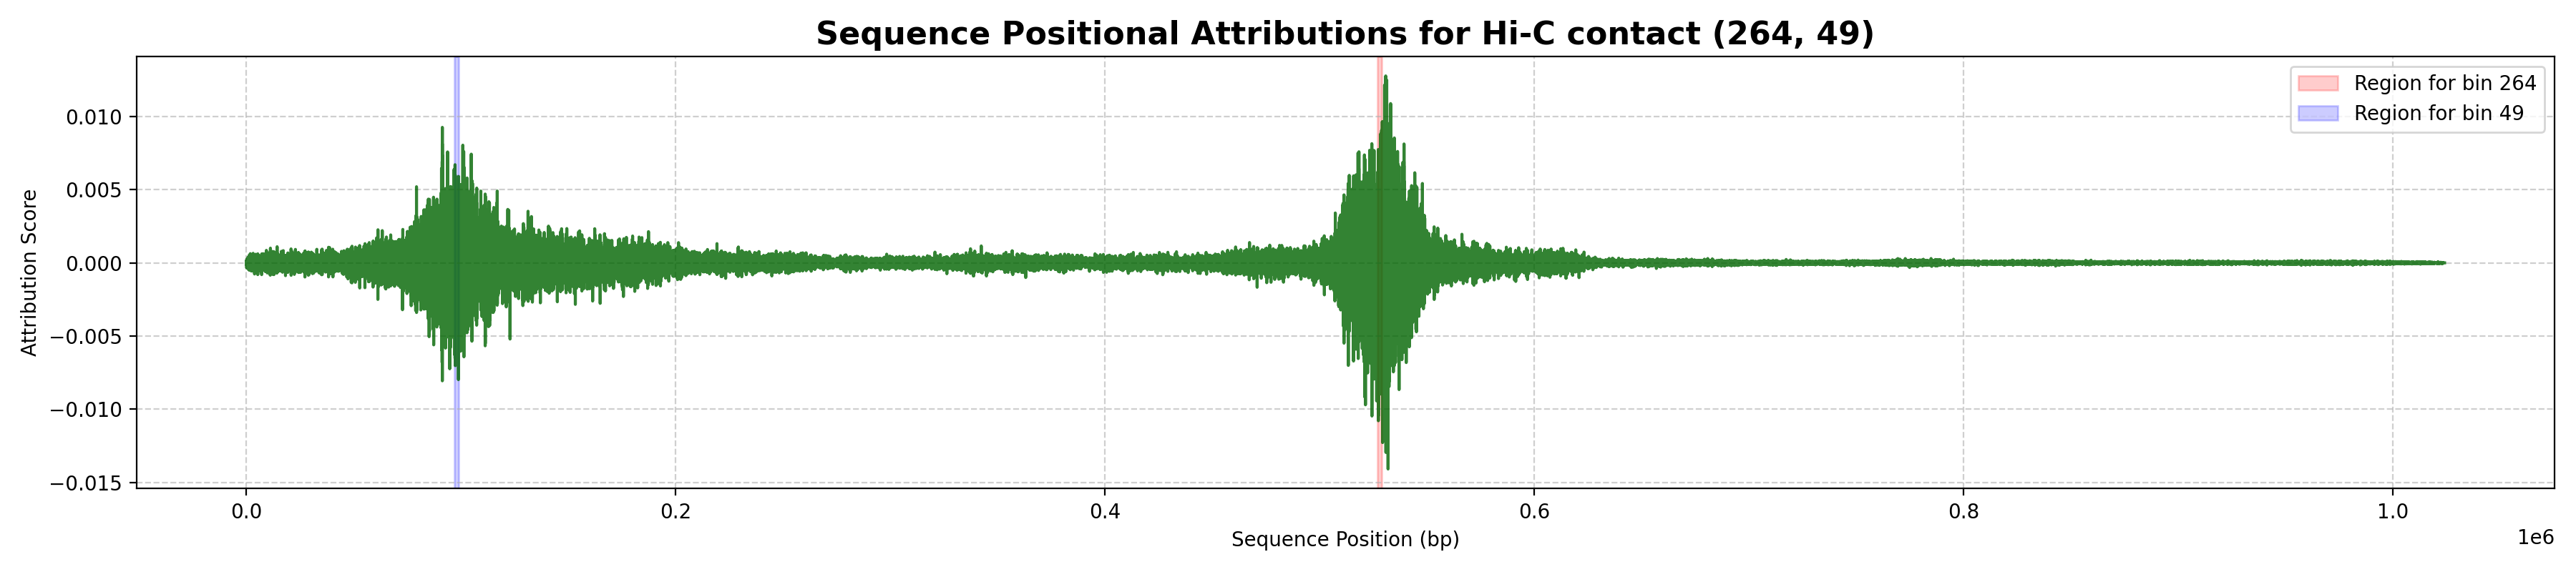

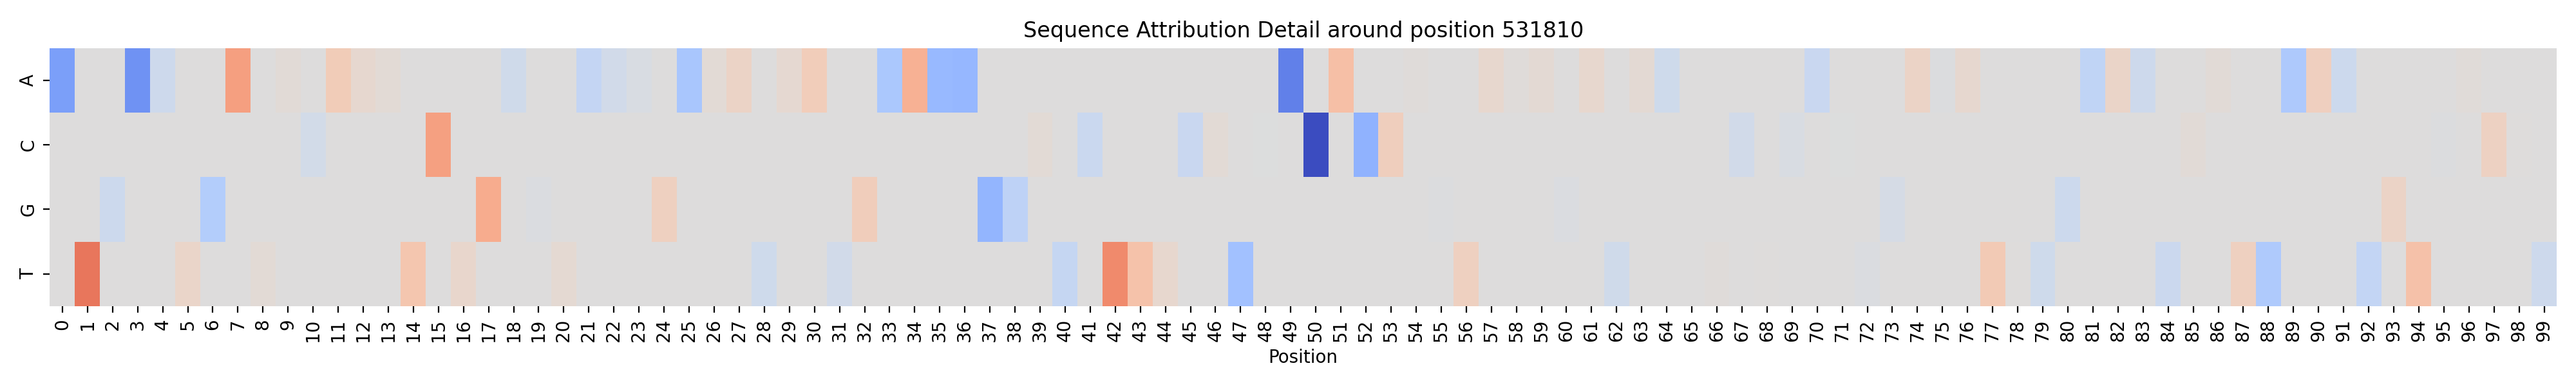

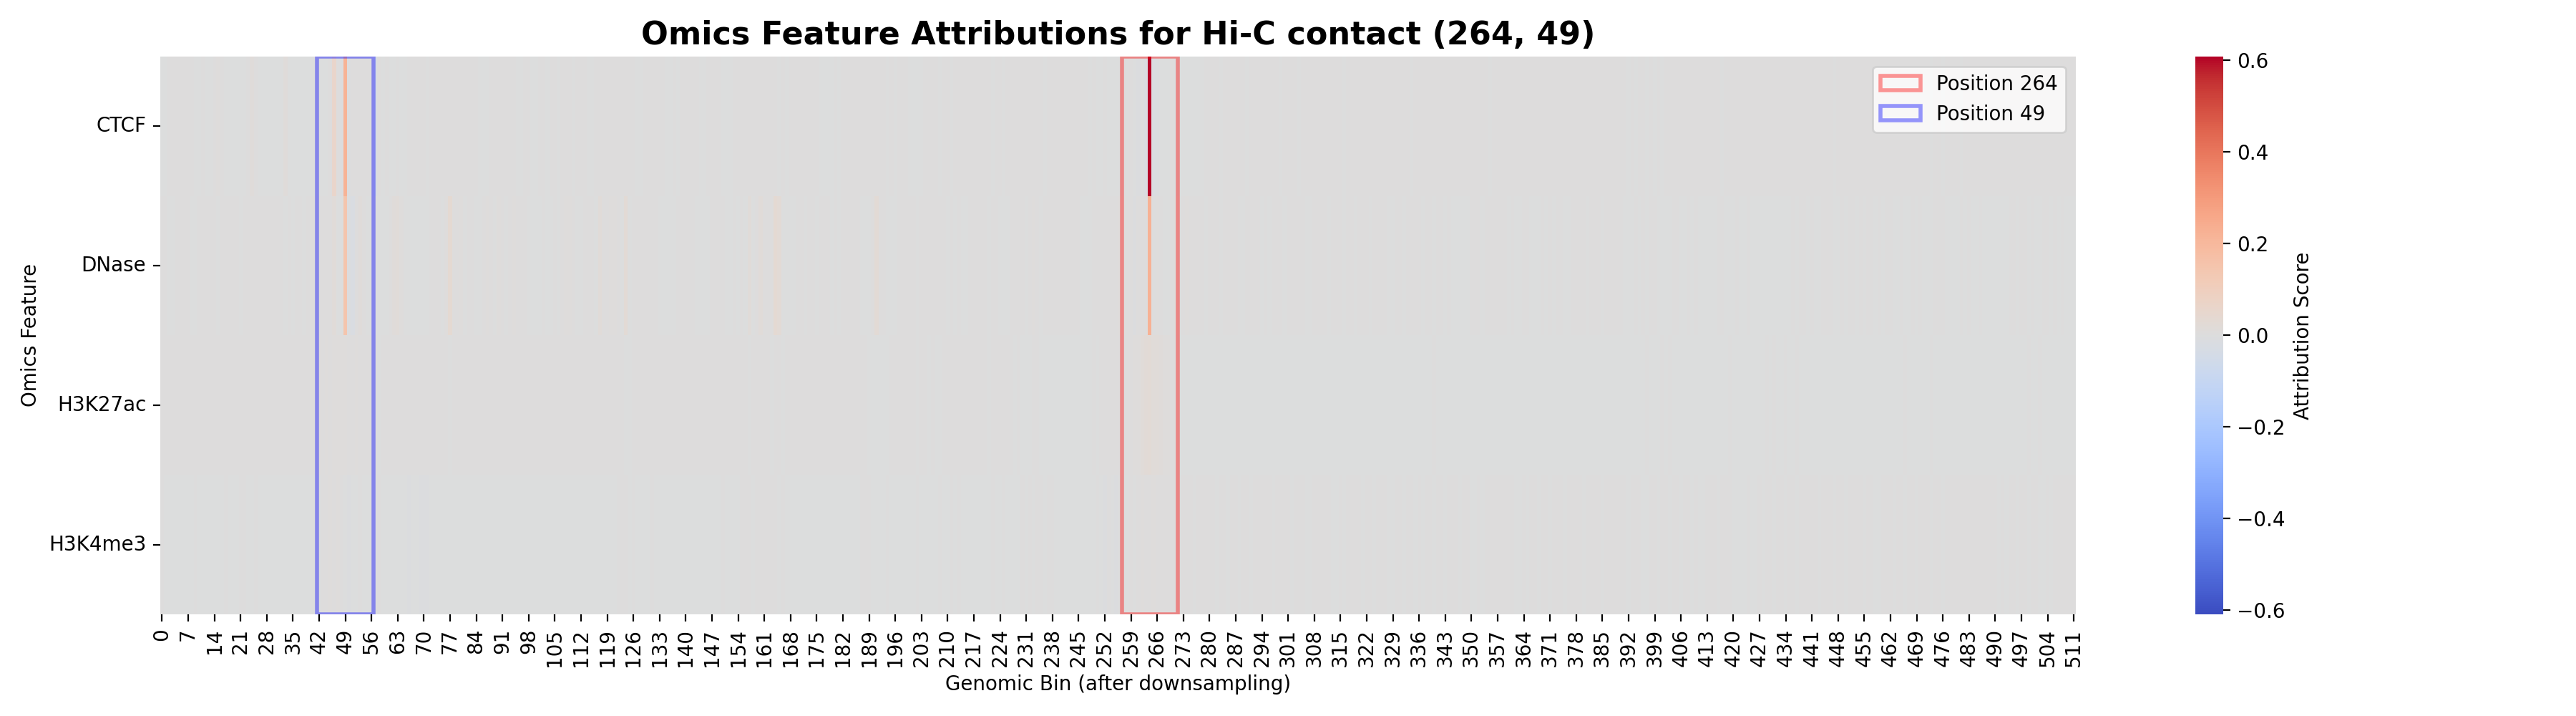

In [13]:
positional = (seq_attr * seq.numpy()).sum(axis=0)
(fig, ax) = plt.subplots(figsize=(18, 4))
ax.plot(positional, color='darkgreen', alpha=0.8)
ax.axvspan(TARGET_I * 2000 - 1000, TARGET_I * 2000 + 1000, color='red', alpha=0.2, label=f'Region for bin {TARGET_I}')
ax.axvspan(TARGET_J * 2000 - 1000, TARGET_J * 2000 + 1000, color='blue', alpha=0.2, label=f'Region for bin {TARGET_J}')
ax.set_title(f'Sequence Positional Attributions for Hi-C contact ({TARGET_I}, {TARGET_J})', fontsize=16, fontweight='bold')
ax.set_xlabel('Sequence Position (bp)')
ax.set_ylabel('Attribution Score')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
fig.tight_layout()
show_figure(fig, dpi=200)
peak = int(np.argmax(np.abs(positional)))
(s, e) = (max(0, peak - 50), min(len(positional), peak + 50))
region_attr = seq_attr[:, s:e] * seq.numpy()[:, s:e]
(fig, ax) = plt.subplots(figsize=(20, 3))
mx = np.abs(region_attr).max()
sns.heatmap(region_attr, cmap='coolwarm', vmin=-mx, vmax=mx, ax=ax, cbar=False, yticklabels=['A', 'C', 'G', 'T'])
ax.set_title(f'Sequence Attribution Detail around position {peak}')
ax.set_xlabel('Position')
fig.tight_layout()
show_figure(fig, dpi=200)
from matplotlib import patches
mx = float(np.abs(omics_attr).max())
(fig, ax) = plt.subplots(figsize=(18, 5))
sns.heatmap(omics_attr, cmap='coolwarm', cbar_kws={'label': 'Attribution Score'}, yticklabels=OMICS_NAMES, vmin=-mx, vmax=mx, ax=ax)
w = 15
for (pos, col, lab) in [(TARGET_I, 'red', f'Position {TARGET_I}'), (TARGET_J, 'blue', f'Position {TARGET_J}')]:
    ax.add_patch(patches.Rectangle((pos - w // 2, 0), w, omics_attr.shape[0], linewidth=2, edgecolor=col, facecolor='none', alpha=0.4, label=lab))
ax.set_title(f'Omics Feature Attributions for Hi-C contact ({TARGET_I}, {TARGET_J})', fontsize=16, fontweight='bold')
ax.set_xlabel('Genomic Bin (after downsampling)')
ax.set_ylabel('Omics Feature')
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(OMICS_NAMES, rotation=0)
ax.legend(loc='upper right')
fig.tight_layout()
show_figure(fig, dpi=200)


## (g-j) Edited tracks, predictions, and changes

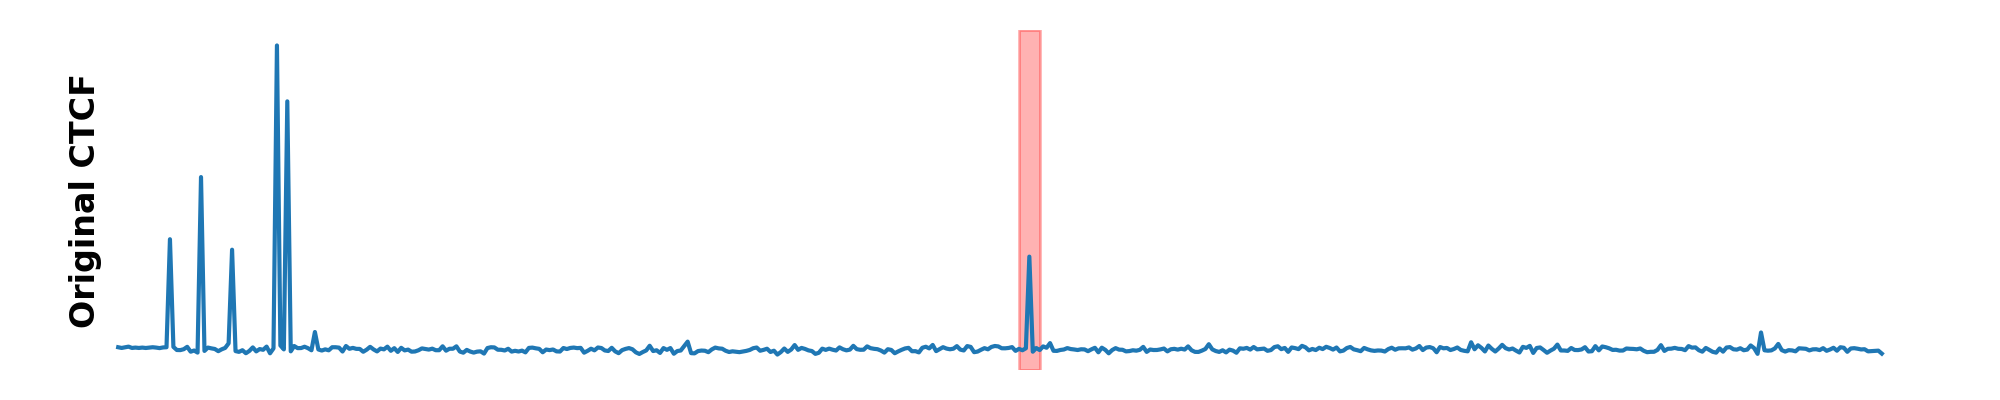

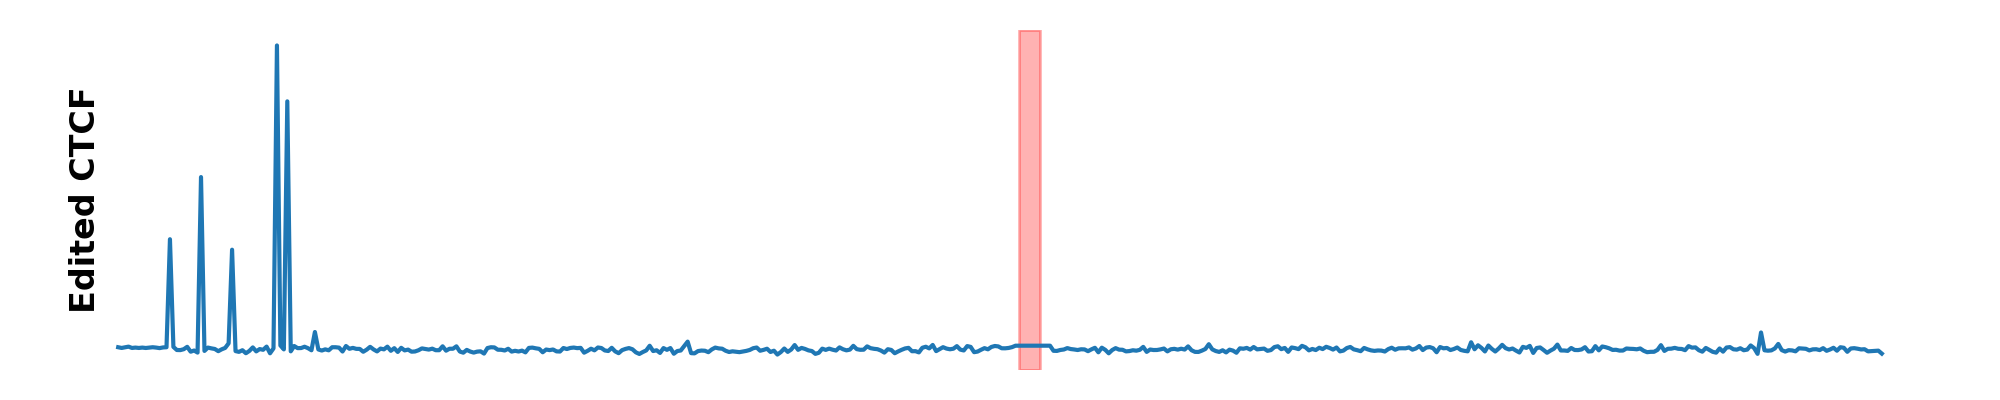

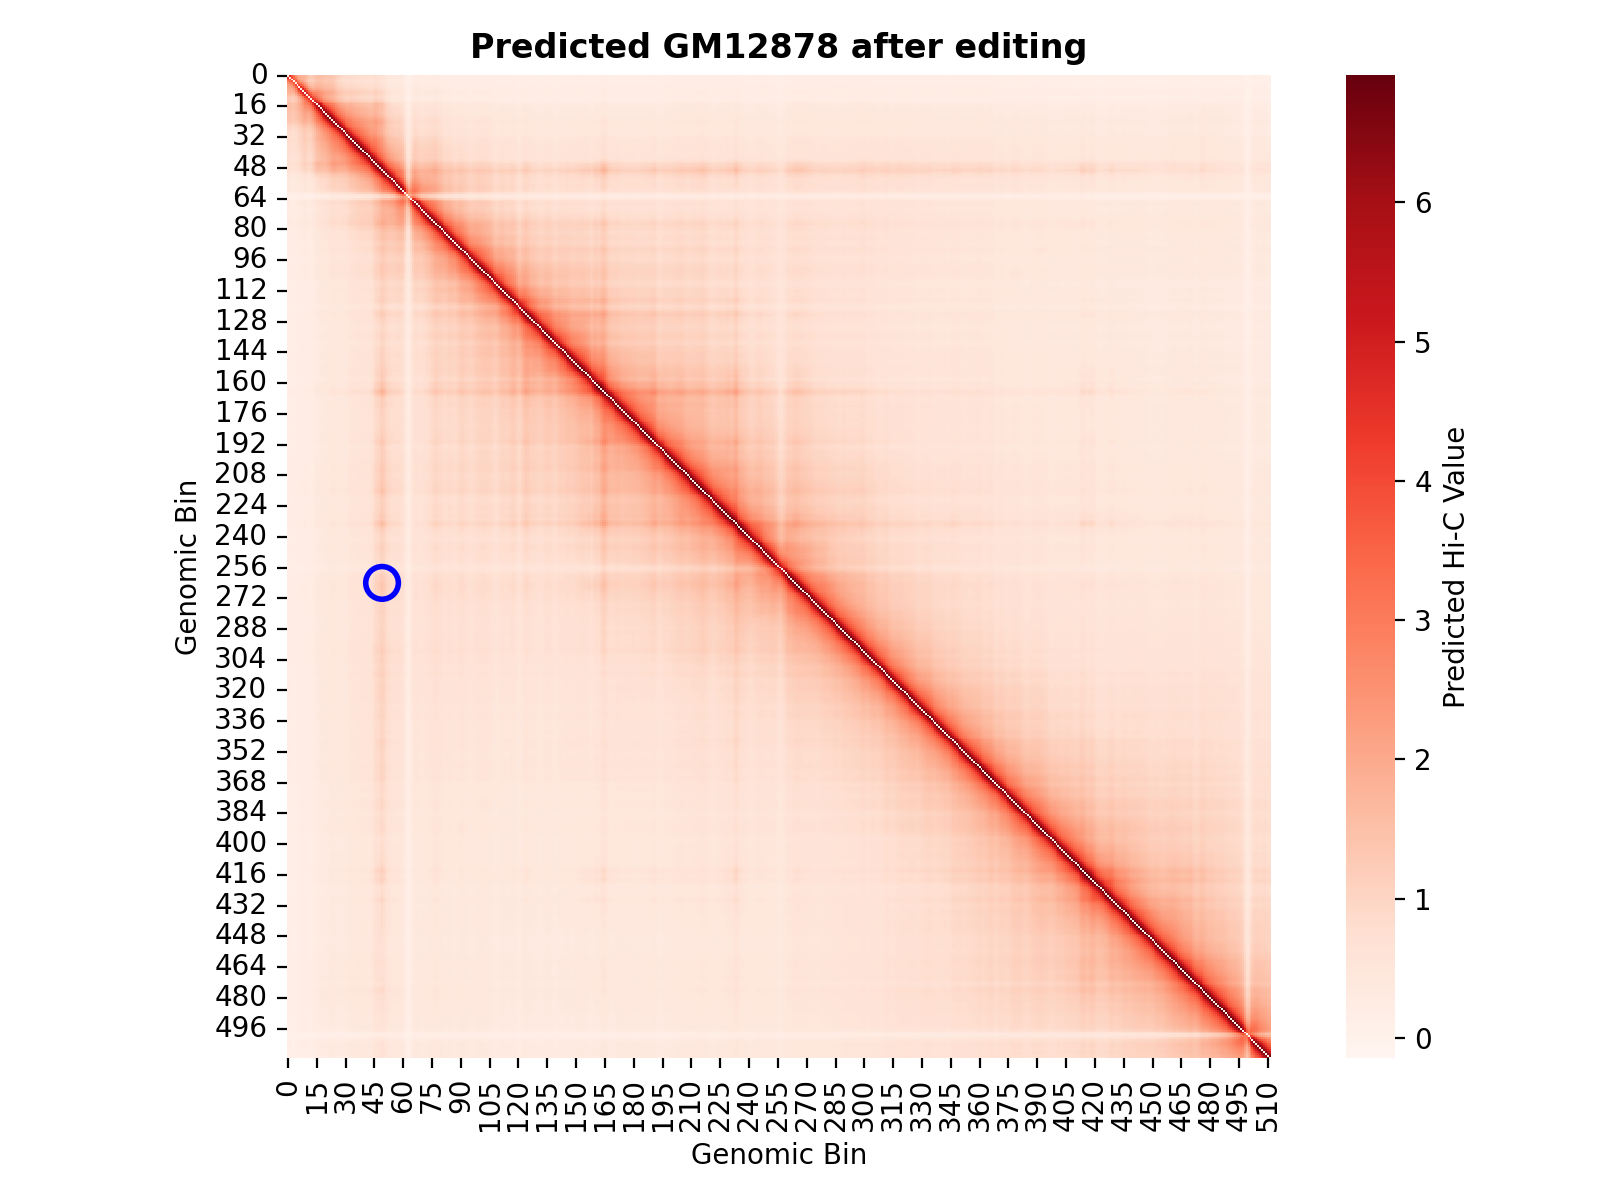

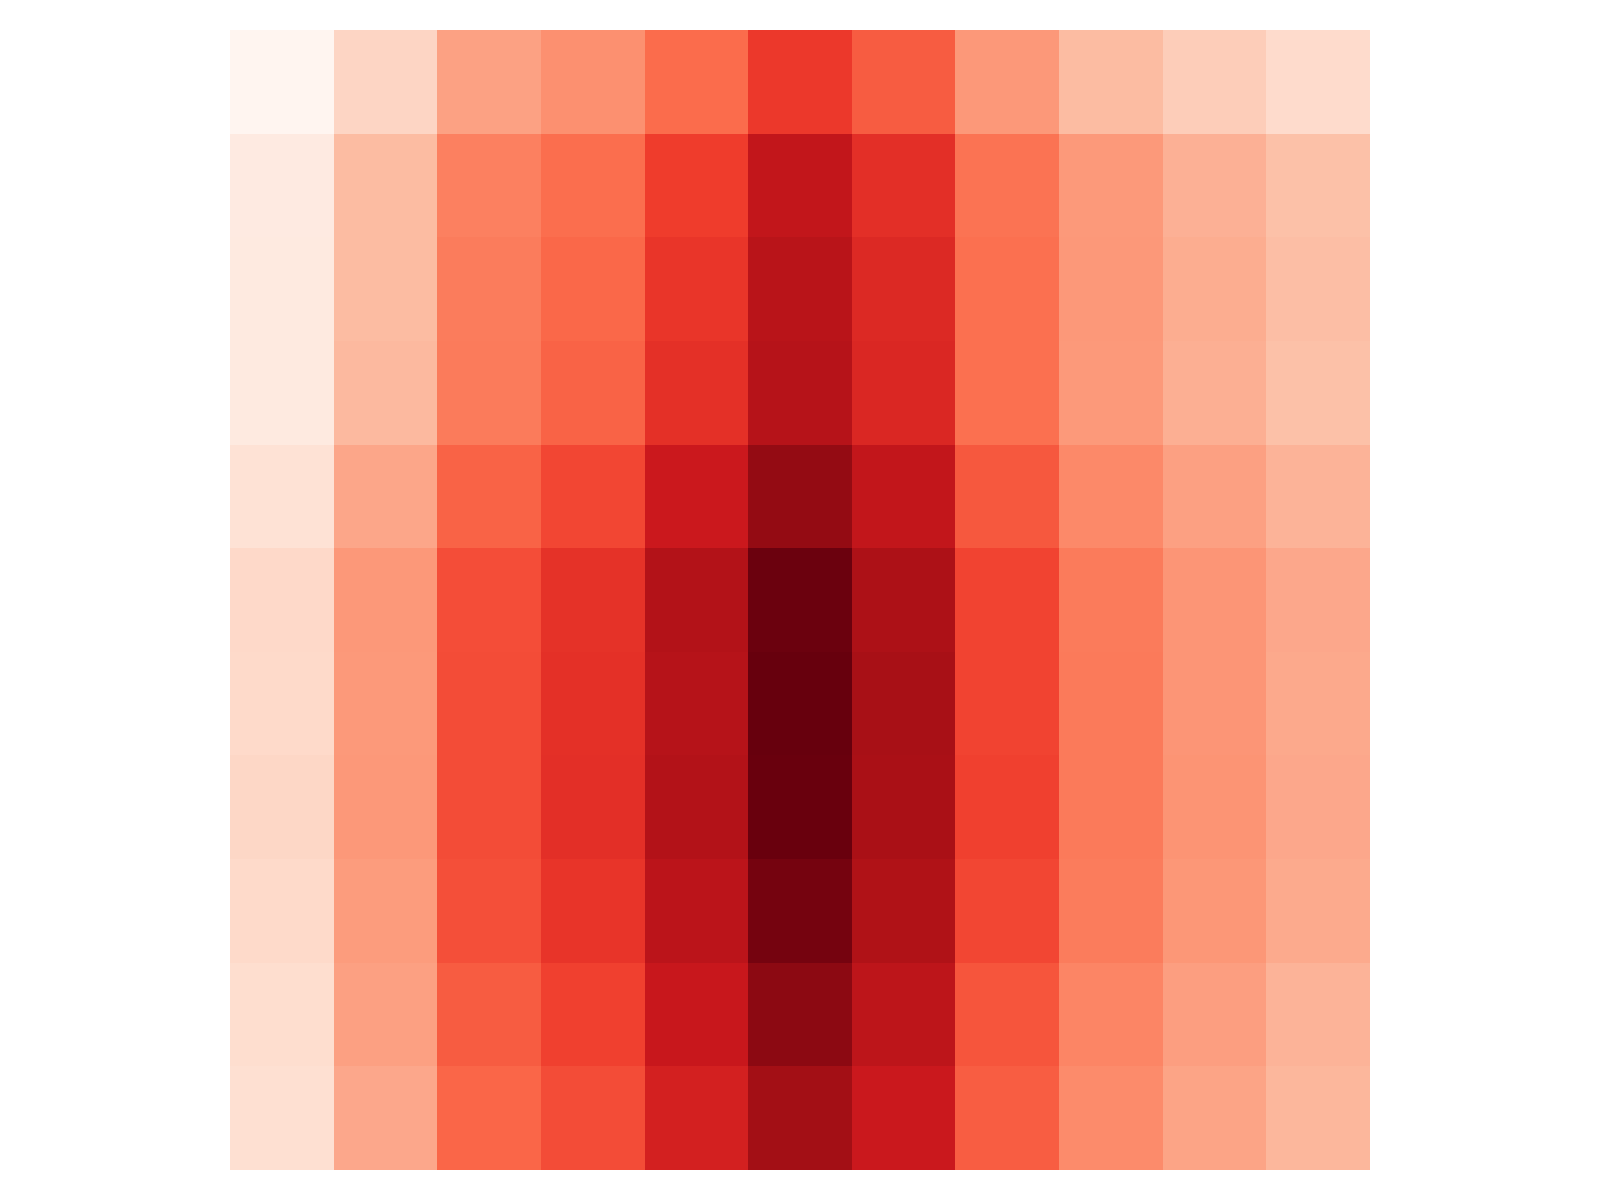

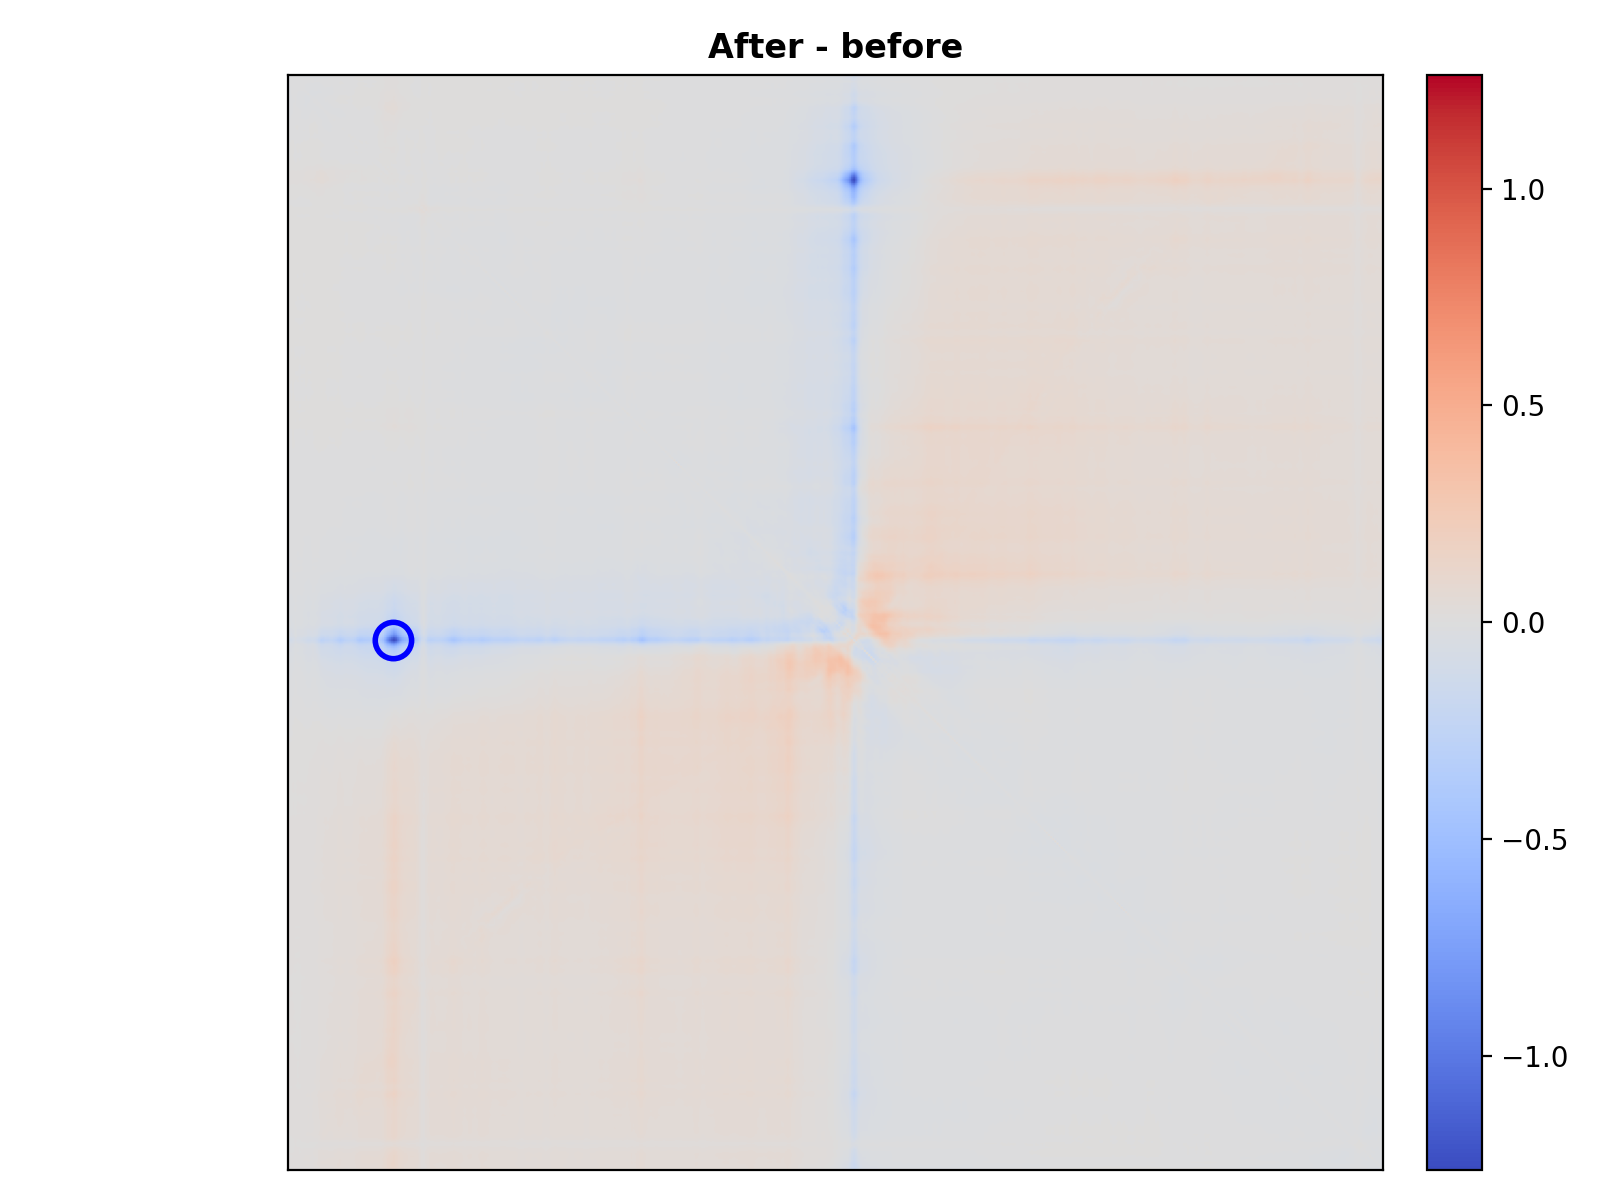

In [14]:
for name, vector in [
    ("Original CTCF", omics[0].numpy()),
    ("Edited CTCF", omics_edit.squeeze(0)[0].cpu().numpy()),
]:
    fig, ax = plt.subplots(figsize=(10, 2))
    ax.plot(vector)
    ax.axvspan(TARGET_I - 3, TARGET_I + 3, color="red", alpha=0.3)
    ax.text(0.02, 0.5, name, transform=ax.transAxes, fontsize=12,
            fontweight="bold", va="center", rotation=90)
    ax.axis("off")
    fig.tight_layout()
    show_figure(fig)

pred_panel(pred_after, 'Predicted GM12878 after editing')
inset_panel(pred_after, 'after')
diff = pred_after - pred_before
lim = float(max(abs(np.nanmin(diff)), abs(np.nanmax(diff)), 1e-06))
(fig, ax) = plt.subplots(figsize=(8, 6))
im = ax.imshow(diff, cmap='coolwarm', vmin=-lim, vmax=lim)
ax.set_title('After - before', fontweight='bold')
ax.set_xticks([])
ax.set_yticks([])
from matplotlib.patches import Circle
ax.add_patch(Circle((TARGET_J, TARGET_I), radius=8.5, fill=False, edgecolor='blue', linewidth=2.0))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.tight_layout()
show_figure(fig, dpi=200)
